# ORBIT p-Bit vs p-Dit: Categorical Assignment Representation Experiment

**Research question:** does representing each task assignment as one categorical p-dit
(one variable per task, whose states are its sensor-eligible UAVs) improve ORBIT sampling and
ground-state recovery relative to the existing one-hot p-bit QUBO representation
(several binary variables per task plus an exactly-one penalty)?

Everything downstream of the representation is held identical to
[`orbit_solve_and_performance.ipynb`](orbit_solve_and_performance.ipynb): the same
`small_seed_42` scenario, the same V2 operational objective (base proximity + geographic
route-merge + target workload), the same nearest-neighbour sequencing, the same validator, the
same metrics. The only thing that changes is the sampler-facing variable representation.

This notebook does not modify `orbit_solve_and_performance.ipynb`, which remains the canonical
p-bit benchmark.

## 1. ORBIT SDK capability inspection

Before writing any solver code, the locally installed ORBIT SDK was inspected directly (source
reading, not documentation) for genuine categorical/p-dit support. Summary of what was found —
full detail in the accompanying README section and module docstrings
(`solvers/orbit/pdit_backend.py`, `solvers/orbit/pdit_encoding.py`):

- **`orbit_sdk.problems.MIQPProblem`** (beta) auto-detects any constraint of the form
  `sum(x_i) == 1` with unit coefficients and *at least 2 variables* as a **"PDIT group"**, and
  removes it from penalty-based constraint handling.
- **`orbit_simulator`'s replica step** (`components/replica.py`) performs a genuine **joint
  categorical (softmax) draw** across all members of a PDIT group every sweep — confirmed by
  reading the simulator's own Monte Carlo update code, not inferred from naming. This is real
  multi-state sampling, not a QUBO penalty in disguise.
- **Known SDK gap** (confirmed by diffing `problems/base.py` against `problems/miqp.py`):
  `MIQPProblem.model_post_init` never populates `_adjacency` / `_update_groups`, so
  `SimulatorSolver.solve()` fails immediately with `AttributeError` on any `MIQPProblem`. This
  notebook's backend (`OrbitPditSimulatorBackend`) closes that gap using the SDK's own public
  `generate_adjacency_for_miqp` / `generate_update_groups` functions — the same ones the SDK's
  own test suite (`tests/test_miqp.py`) imports. **orbit_sdk itself is not modified.**
- **Cardinality-1 caveat**: a PDIT group must have at least 2 states. Tasks with only one
  sensor-eligible UAV (9 of 16 in this scenario) are therefore *not* registered as genuine PDIT
  groups — their assignment constraint falls back to an ordinary Lagrangian-penalty equality
  constraint, which can rarely be violated by the stochastic sampler. This is handled explicitly
  below (deterministic repair, counted) rather than hidden.

**Conclusion: native p-dit execution is genuinely supported and was used for every ORBIT result
in this notebook — this is not a QUBO fallback.**

In [7]:
import orbit_sdk
from orbit_sdk.problems import MIQPProblem
from orbit_sdk.solvers import SimulatorSolver

print(f"orbit_sdk version:            {getattr(orbit_sdk, '__version__', 'unknown')}")
print(f"Native p-dit support detected: True  (orbit_sdk.problems.MIQPProblem + PDIT auto-detection)")
print(f"Relevant API:                  orbit_sdk.problems.MIQPProblem, orbit_sdk.solvers.SimulatorSolver,")
print(f"                               orbit_sdk.toolkit.graph.generate_adjacency_for_miqp/generate_update_groups")
print(f"Backend used:                  SimulatorSolver (local simulator, MIQPCalculator)")
print(f"Hardware execution:            False")

orbit_sdk version:            0.0.0
Native p-dit support detected: True  (orbit_sdk.problems.MIQPProblem + PDIT auto-detection)
Relevant API:                  orbit_sdk.problems.MIQPProblem, orbit_sdk.solvers.SimulatorSolver,
                               orbit_sdk.toolkit.graph.generate_adjacency_for_miqp/generate_update_groups
Backend used:                  SimulatorSolver (local simulator, MIQPCalculator)
Hardware execution:            False


## 2. Load the scenario

medium_seed_42: 75 tasks, 15 UAVs, 3 bases


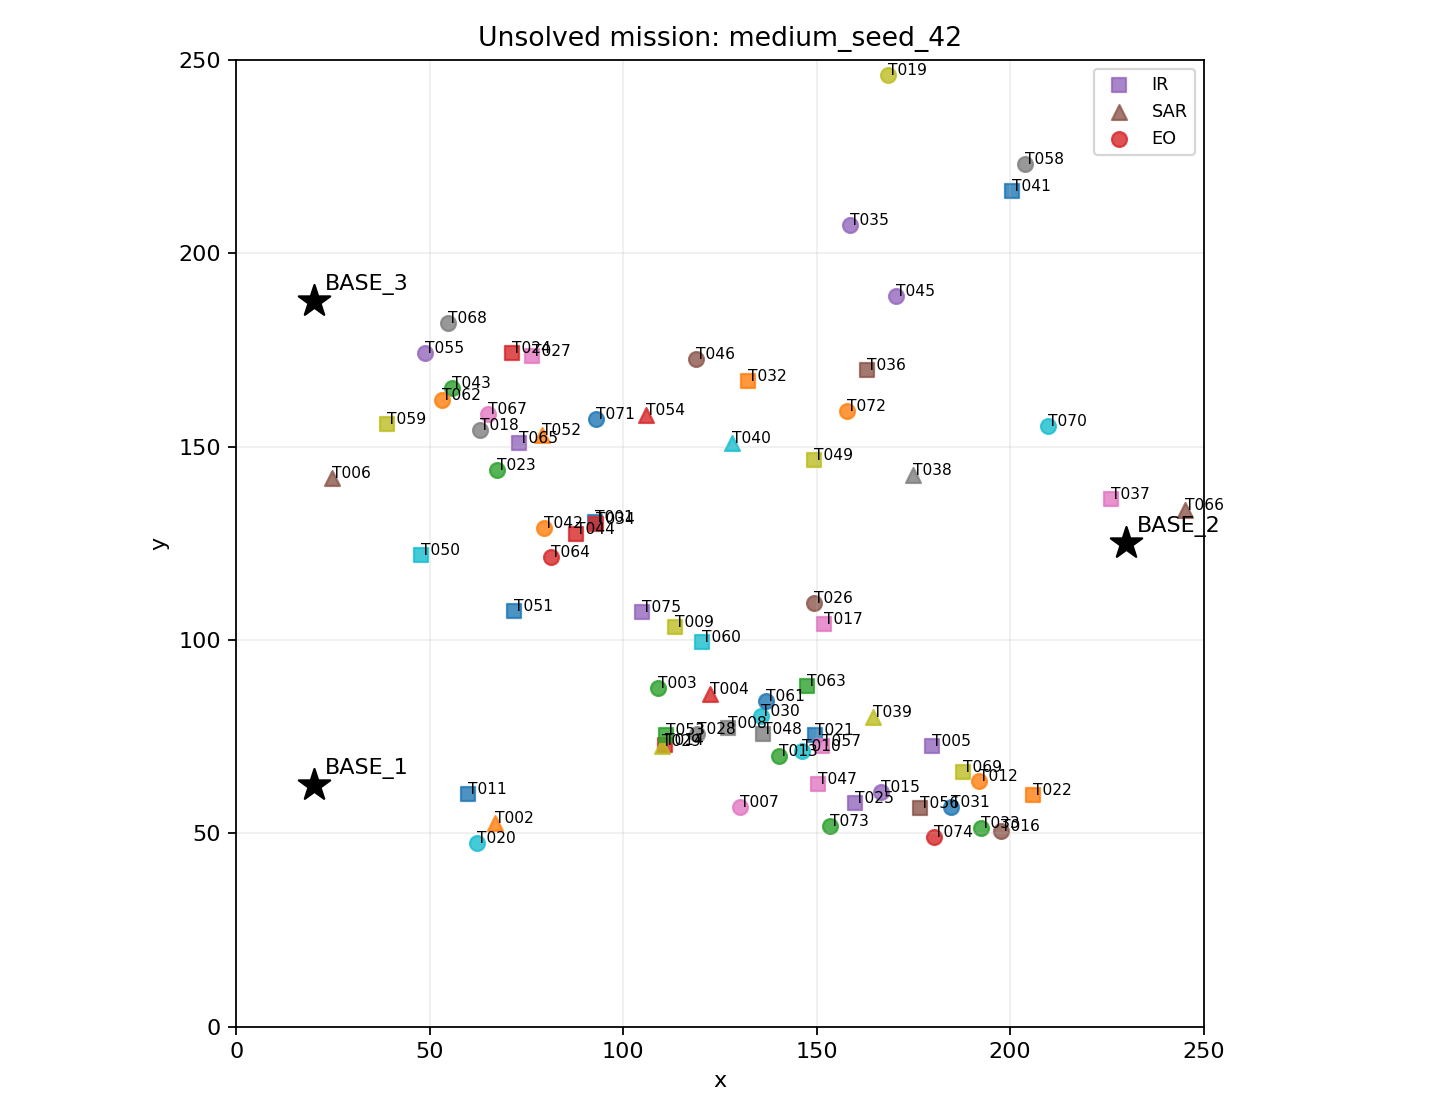

In [8]:
from pathlib import Path

from IPython.display import Image

from isr_mission_planning.benchmark.energy import compute_qubo_energy
from isr_mission_planning.benchmark.ground_state import solve_qubo_exact
from isr_mission_planning.benchmark.orbit_sampling import run_orbit_sampling
from isr_mission_planning.benchmark.pdit_ground_state import energy_equivalence_check, solve_categorical_exact
from isr_mission_planning.benchmark.pdit_sampling import run_pdit_sampling
from isr_mission_planning.benchmark.sample_analysis import summarise_samples
from isr_mission_planning.evaluation import validate_plan
from isr_mission_planning.generation import generate_scenario
from isr_mission_planning.solvers import GreedySolver, OrbitHybridSolver, OrbitPditSolver, SolverConfig
from isr_mission_planning.solvers.orbit import OrbitSolver
from isr_mission_planning.solvers.orbit.encoding_v2 import GeographicAssignmentV2Encoding, GeographicV2Config
from isr_mission_planning.solvers.orbit.pdit_encoding import (
    build_categorical_v2_model, compute_pdit_energy, one_hot_to_assignment,
)
from isr_mission_planning.visualisation import plot_gantt, plot_mission_map
from isr_mission_planning.visualisation.mission_map import plot_scenario

FIGURE_DIR = Path("../outputs/figures/pdit")
BENCHMARK_DIR = Path("../outputs/benchmark/pdit")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)
BENCHMARK_DIR.mkdir(parents=True, exist_ok=True)

scenario = generate_scenario("medium", seed=42)
print(f"{scenario.scenario_id}: {len(scenario.tasks)} tasks, {len(scenario.uavs)} UAVs, {len(scenario.bases)} bases")
plot_scenario(scenario, FIGURE_DIR / "unsolved_mission.png")
Image(str(FIGURE_DIR / "unsolved_mission.png"))

## 3. p-Bit representation (recap)

For every eligible UAV-task pair, `assign::{uav}::{task}` is a binary p-bit. Every task's
"exactly one UAV" constraint is enforced as a *penalty term*
`assignment_penalty * [(sum x - 1)^2 - 1]` inside the QUBO energy — a soft constraint the sampler
must learn to satisfy.

In [9]:
v2_config = GeographicV2Config(assignment_penalty=12.0, base_weight=0.75, cluster_weight=0.25, workload_weight=1.5)
v2_encoding = GeographicAssignmentV2Encoding(v2_config).encode(scenario)

print(f"p-bit variables:      {len(v2_encoding.variable_order)}")
print(f"assignment penalty:   {v2_config.assignment_penalty}  (present in every sample's energy)")
print(f"quadratic interactions present in Q: {sum(1 for i in range(len(v2_encoding.variable_order)) for j in range(i+1, len(v2_encoding.variable_order)) if v2_encoding.qubo_matrix[i][j] != 0)}")

p-bit variables:      598
assignment penalty:   12.0  (present in every sample's energy)
quadratic interactions present in Q: 16239


## 4. p-Dit representation

Each task becomes **one categorical variable** whose states are its sensor-eligible UAVs. The
exactly-one constraint disappears — it is guaranteed by the categorical domain itself, not by a
penalty term. The categorical model is derived directly from the same V2 objective's component
matrices (`base_proximity`, `geographic_cluster`, `workload_balance`), excluding the `feasibility`
(assignment-penalty) component entirely, so both representations share the same underlying
operational objective by construction.

In [10]:
model = build_categorical_v2_model(scenario, v2_config)

print(f"p-dit variables (tasks): {len(model.task_states)}")
print(f"assignment penalty:      none (E_assignment = 0 by construction)")
print(f"unary terms:             {len(model.unary)}")
print(f"pairwise categorical interaction terms: {len(model.pairwise)}")

cardinalities = [len(uavs) for uavs in model.task_states.values()]
print(f"cardinality  min/mean/max: {min(cardinalities)} / {sum(cardinalities)/len(cardinalities):.2f} / {max(cardinalities)}")

p-dit variables (tasks): 75
assignment penalty:      none (E_assignment = 0 by construction)
unary terms:             598
pairwise categorical interaction terms: 13581
cardinality  min/mean/max: 1 / 7.97 / 12


In [11]:
import pandas as pd

table = pd.DataFrame(model.cardinality_table())
table

,task_id,eligible_uavs,cardinality
0,TASK_001,"(UAV_02, UAV_09, UAV_11, UAV_12, UAV_13, UAV_14)",6
1,TASK_002,"(UAV_03,)",1
2,TASK_003,"(UAV_01, UAV_02, UAV_04, UAV_05, UAV_06, UAV_0...",12
3,TASK_004,"(UAV_03,)",1
4,TASK_005,"(UAV_02, UAV_09, UAV_11, UAV_12, UAV_13, UAV_14)",6
...,...,...,...
70,TASK_071,"(UAV_01, UAV_02, UAV_04, UAV_05, UAV_06, UAV_0...",12
71,TASK_072,"(UAV_01, UAV_02, UAV_04, UAV_05, UAV_06, UAV_0...",12
72,TASK_073,"(UAV_01, UAV_02, UAV_04, UAV_05, UAV_06, UAV_0...",12
73,TASK_074,"(UAV_01, UAV_02, UAV_04, UAV_05, UAV_06, UAV_0...",12


## 5. Representation comparison

Only the *genuinely multi-choice* tasks (cardinality ≥ 2) are registered by the installed SDK as
real PDIT groups with structurally-guaranteed joint sampling; single-choice tasks fall back to an
ordinary penalty constraint (see Section 1).

In [12]:
multi_choice = sum(1 for c in cardinalities if c >= 2)
single_choice = sum(1 for c in cardinalities if c == 1)

print("p-bit:")
print(f"  {len(v2_encoding.variable_order)} binary variables")
print(f"  exactly-one assignment penalty required (weight {v2_config.assignment_penalty})")
print()
print("p-dit:")
print(f"  {len(model.task_states)} categorical variables")
print(f"  {multi_choice} genuine multi-state PDIT groups (structurally-guaranteed joint sampling)")
print(f"  {single_choice} single-choice tasks (only one eligible UAV; penalty-enforced, not joint-sampled)")
print(f"  no exactly-one penalty term")

p-bit:
  598 binary variables
  exactly-one assignment penalty required (weight 12.0)

p-dit:
  75 categorical variables
  65 genuine multi-state PDIT groups (structurally-guaranteed joint sampling)
  10 single-choice tasks (only one eligible UAV; penalty-enforced, not joint-sampled)
  no exactly-one penalty term


## 6. Independent p-bit/p-dit energy-equivalence validation

For any *valid* one-hot assignment, the p-bit assignment-penalty component always contributes
exactly `-assignment_penalty * n_tasks` (a constant — see `encoding_v2.py`'s "constant-shifted"
comment). Subtracting that constant should make the p-bit operational energy equal the
independently-computed p-dit energy. Checked at the V2 exact ground state, the greedy assignment,
and 100 seeded random valid assignments — using `compute_pdit_energy`, a dict-based evaluator that
never touches the QUBO matrix.

Both exact-MILP calls below (`solve_qubo_exact`, `solve_categorical_exact`) are capped with
`EXACT_TIME_LIMIT_SECONDS` — an unbounded brute-force exact solve is fine at this scenario's small
size (37 p-bit / 16 p-dit variables), but the same call becomes a ~17,000-variable MILP at medium
scale (see the project README), so this notebook never assumes it will always be small. If the cap
is hit, the result is reported honestly as a best-found bound, not a proven ground state.

In [13]:
EXACT_TIME_LIMIT_SECONDS = 60

v2_exact = solve_qubo_exact(v2_encoding, time_limit_seconds=EXACT_TIME_LIMIT_SECONDS)
if not v2_exact.optimality_proven:
    print(f"WARNING: p-bit exact solve hit the {EXACT_TIME_LIMIT_SECONDS}s cap "
          f"(status={v2_exact.status}, mip_gap={v2_exact.mip_gap}); using best-found, not a proven ground state.")

ground_mapping = {var.meaning["task_id"]: var.meaning["uav_id"]
                  for bit, var in zip(v2_exact.ground_state, v2_encoding.variables, strict=True) if bit}
check_ground = energy_equivalence_check(ground_mapping, model, v2_encoding, v2_config.assignment_penalty)

greedy_plan_for_check = GreedySolver().solve(scenario).mission_plan
greedy_assignment = {a.task_id: a.uav_id for a in greedy_plan_for_check.task_assignments}
check_greedy = energy_equivalence_check(greedy_assignment, model, v2_encoding, v2_config.assignment_penalty)

import random
rng = random.Random(7)
random_agreements = 0
for _ in range(100):
    assignment = {task.id: rng.choice([u.id for u in scenario.uavs if task.required_sensor in u.sensors])
                 for task in scenario.tasks}
    random_agreements += energy_equivalence_check(assignment, model, v2_encoding, v2_config.assignment_penalty)["agrees"]

print(f"agrees @ V2 exact ground state:  {check_ground['agrees']}  (diff={check_ground['difference']:.2e})")
print(f"agrees @ greedy assignment:      {check_greedy['agrees']}  (diff={check_greedy['difference']:.2e})")
print(f"agrees across 100 random valid assignments: {random_agreements}/100")

agrees @ V2 exact ground state:  True  (diff=-9.24e-14)
agrees @ greedy assignment:      True  (diff=-2.84e-14)
agrees across 100 random valid assignments: 100/100


## 7. Exact p-dit ground state, and its relationship to the exact p-bit ground state

In [14]:
categorical_exact = solve_categorical_exact(model, time_limit_seconds=EXACT_TIME_LIMIT_SECONDS)
same_state = categorical_exact.ground_state == v2_exact.ground_state

print(f"exact categorical ground energy: {categorical_exact.ground_state_energy:.6f}")
print(f"optimality proven:               {categorical_exact.optimality_proven}")
print(f"runtime:                         {categorical_exact.runtime_seconds:.3f}s")
if not categorical_exact.optimality_proven:
    print(f"WARNING: p-dit exact solve hit the {EXACT_TIME_LIMIT_SECONDS}s cap "
          f"(status={categorical_exact.status}, mip_gap={categorical_exact.mip_gap}); using best-found, not a proven ground state.")
print(f"same semantic assignment as V2 p-bit exact optimum: {same_state}"
      + ("" if (v2_exact.optimality_proven and categorical_exact.optimality_proven)
         else "  (not a meaningful comparison: at least one side is not a proven optimum)"))

exact categorical ground energy: -30.865156
optimality proven:               False
runtime:                         60.160s
same semantic assignment as V2 p-bit exact optimum: False  (not a meaningful comparison: at least one side is not a proven optimum)


## 8. Native ORBIT p-dit solve (single run)

Uses the real local ORBIT SDK simulator via `orbit_sdk.problems.MIQPProblem` — genuine joint
categorical sampling, not a compiled-down QUBO.

In [15]:
config = SolverConfig(seed=42, orbit_full_sweeps=500, orbit_replicas=4, orbit_processes=1)
pdit_result = OrbitPditSolver().solve(scenario, config)
pdit_plan = pdit_result.mission_plan
pdit_report = validate_plan(scenario, pdit_plan)

print(f"status:      {pdit_result.status.value}")
print(f"feasible:    {pdit_report.feasible}")
print(f"makespan:    {pdit_report.metrics.makespan:.2f}")
print(f"runtime:     {pdit_result.runtime_seconds:.3f}s")
print()
print("time breakdown:")
for key in ("encoding_time", "orbit_execution_time", "decoding_time"):
    print(f"  {key:22s} {pdit_result.solver_metadata[key]:.3f}s")
print()
print(f"raw p-dit energy:            {pdit_result.solver_metadata['raw_pdit_energy']:.6f}")
print(f"exact categorical optimum:   {categorical_exact.ground_state_energy:.6f}")
print(f"gap to optimum:              {pdit_result.solver_metadata['raw_pdit_energy'] - categorical_exact.ground_state_energy:.6f}")
print(f"single-option task repairs:  {pdit_result.solver_metadata['single_option_task_repairs']}")
print(f"native_pdit_execution:       {pdit_result.solver_metadata['native_pdit_execution']}")

status:      FEASIBLE
feasible:    True
makespan:    79.83
runtime:     195.729s

time breakdown:
  encoding_time          0.075s
  orbit_execution_time   195.640s
  decoding_time          0.013s

raw p-dit energy:            -24.842643
exact categorical optimum:   -30.865156
gap to optimum:              6.022513
single-option task repairs:  0
native_pdit_execution:       True


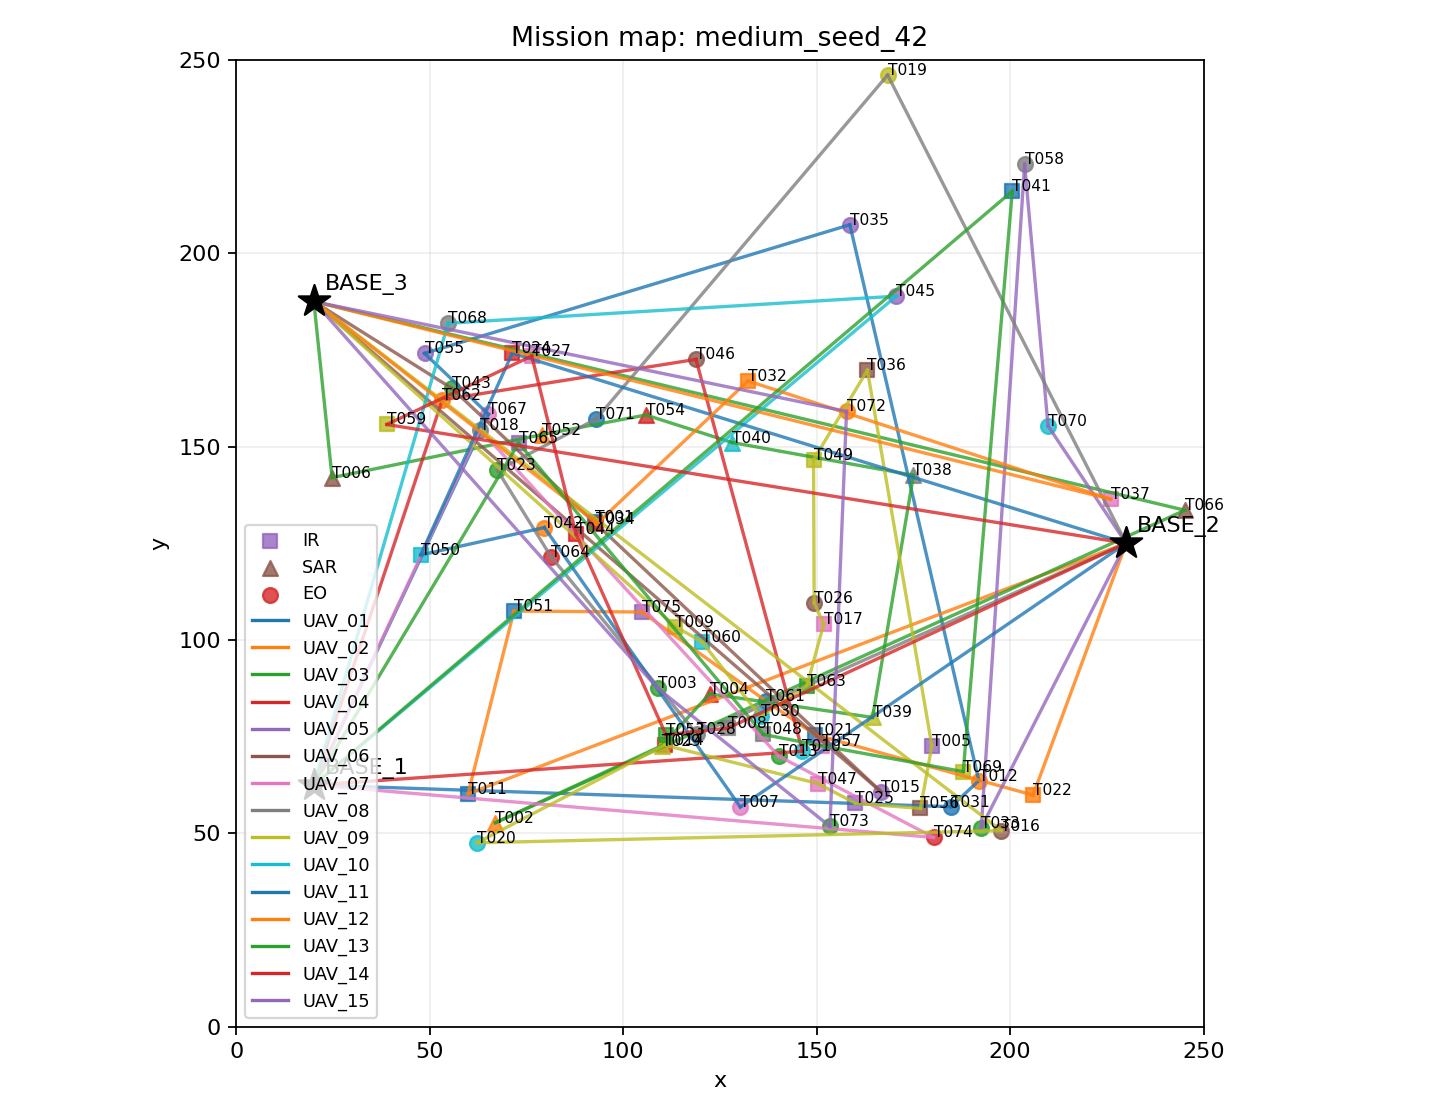

In [16]:
plot_mission_map(scenario, pdit_plan, FIGURE_DIR / "pdit_mission_map.png")
Image(str(FIGURE_DIR / "pdit_mission_map.png"))

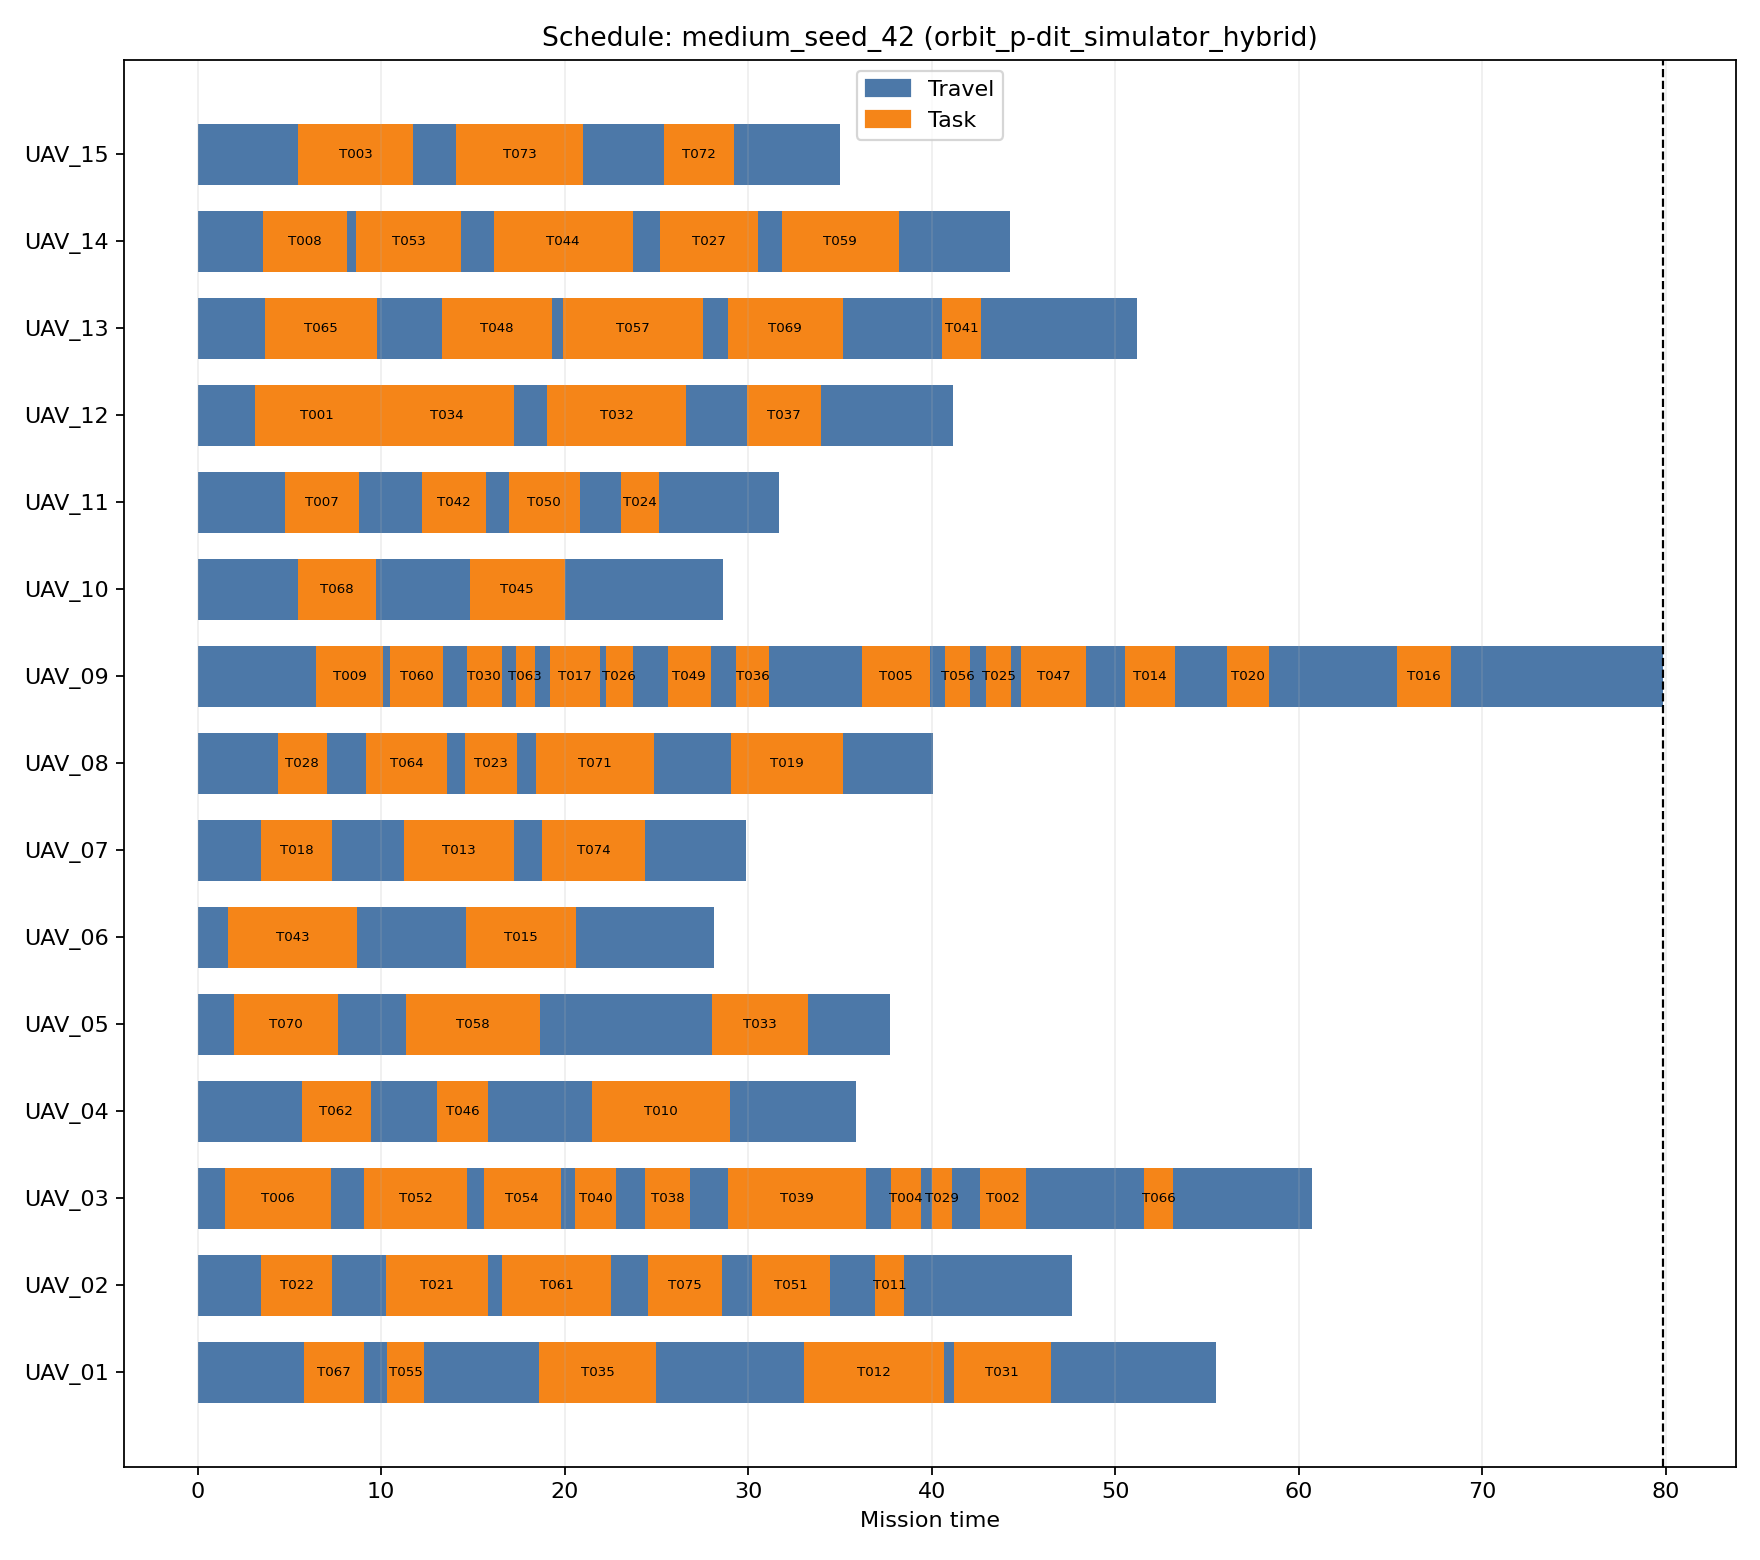

In [17]:
plot_gantt(pdit_plan, FIGURE_DIR / "pdit_gantt.png")
Image(str(FIGURE_DIR / "pdit_gantt.png"))

## 9. Raw reliability study: p-bit vs p-dit

Same protocol as the p-bit notebook: 5 runs x 2,000 samples each, with **no** local refinement —
raw sampler output only, independently energy-audited.

In [18]:
from isr_mission_planning.benchmark.sample_analysis import wilson_interval

REPEATS = 5
SAMPLES_PER_RUN = 2000

pbit_runs = [run_orbit_sampling(v2_encoding, SAMPLES_PER_RUN, repeat=i, config=config) for i in range(REPEATS)]
pbit_states = [state for run in pbit_runs for state in run.states]
pbit_summary = summarise_samples(pbit_states, v2_encoding, v2_exact.ground_state_energy)

pdit_runs = [run_pdit_sampling(model, SAMPLES_PER_RUN, repeat=i, config=config) for i in range(REPEATS)]
pdit_energies = [e for run in pdit_runs for e in run.independently_audited_energies]
pdit_assignments = [a for run in pdit_runs for a in run.assignments]
pdit_hits = sum(1 for e in pdit_energies if abs(e - categorical_exact.ground_state_energy) <= 1e-8)
pdit_unique = len({tuple(sorted(a.items())) for a in pdit_assignments})
pdit_ci = wilson_interval(pdit_hits, len(pdit_energies))

print(f"{'metric':<38}{'p-bit raw':>16}{'p-dit raw':>16}")
print("-" * 70)
print(f"{'samples':<38}{pbit_summary.number_of_samples:>16}{len(pdit_energies):>16}")
print(f"{'ground-state hits':<38}{pbit_summary.ground_state_samples:>16}{pdit_hits:>16}")
print(f"{'ground-state hit rate':<38}{pbit_summary.ground_state_sample_fraction:>15.4%}{pdit_hits/len(pdit_energies):>16.4%}")
pbit_ci_str = f"[{pbit_summary.confidence_interval_95[0]:.3%}, {pbit_summary.confidence_interval_95[1]:.3%}]"
pdit_ci_str = f"[{pdit_ci[0]:.3%}, {pdit_ci[1]:.3%}]"
print(f"{'95% CI on hit rate':<38}{pbit_ci_str:>16}{pdit_ci_str:>16}")
print(f"{'best energy (own scale)':<38}{pbit_summary.best_energy:>16.4f}{min(pdit_energies):>16.4f}")
print(f"{'mean energy (own scale)':<38}{pbit_summary.mean_energy:>16.4f}{sum(pdit_energies)/len(pdit_energies):>16.4f}")
print(f"{'unique states/assignments':<38}{pbit_summary.unique_states:>16}{pdit_unique:>16}")
print(f"{'unique-state fraction':<38}{pbit_summary.unique_states/pbit_summary.number_of_samples:>15.2%}{pdit_unique/len(pdit_energies):>16.2%}")
pbit_best_of_n = sum(1 for r in pbit_runs if abs(r.best_energy - v2_exact.ground_state_energy) <= 1e-8)
pdit_best_of_n = sum(1 for r in pdit_runs if abs(r.best_energy - categorical_exact.ground_state_energy) <= 1e-8)
print(f"{'runs whose best-of-N hit optimum':<38}{f'{pbit_best_of_n}/{REPEATS}':>16}{f'{pdit_best_of_n}/{REPEATS}':>16}")

metric                                       p-bit raw       p-dit raw
----------------------------------------------------------------------
samples                                          10000           10000
ground-state hits                                    0               0
ground-state hit rate                         0.0000%         0.0000%
95% CI on hit rate                    [0.000%, 0.038%][0.000%, 0.038%]
best energy (own scale)                      -845.0041        -25.1396
mean energy (own scale)                      -828.7356        -19.1913
unique states/assignments                          397           10000
unique-state fraction                           3.97%         100.00%
runs whose best-of-N hit optimum                   0/5             0/5


**Energies are not directly comparable across representations** (the p-dit model excludes the
assignment-penalty constant, so its scale differs from the p-bit QUBO's — see Section 6's
equivalence check for the correct normalisation). The hit-rate, diversity, and best-of-N success
comparisons above are on each representation's *own* ground-state reference, which is the valid
cross-representation comparison.

## 10. The mixing hypothesis

**p-bit:** reassigning a task from UAV A to UAV B requires a coordinated two-bit move
(`x_A,t: 1→0` and `x_B,t: 0→1` simultaneously) to stay in the exactly-one-satisfying subspace —
a move the sampler has no special mechanism to propose jointly.

**p-dit:** the same change is a single categorical-state transition (`z_t: A→B`), and for the
7 genuine multi-state PDIT groups in this scenario, that transition is proposed and accepted (or
rejected) as one joint softmax draw every sweep.

This experiment tests whether making task reassignment atomic improves state-space exploration
and access to the ground state — it does not assume the answer in advance.

In [19]:
print(f"p-bit unique-state fraction: {pbit_summary.unique_states/pbit_summary.number_of_samples:.2%}")
print(f"p-dit unique-state fraction: {pdit_unique/len(pdit_energies):.2%}")
print(f"ratio: {(pdit_unique/len(pdit_energies)) / max(pbit_summary.unique_states/pbit_summary.number_of_samples, 1e-9):.1f}x more diverse sampling under the categorical representation")

p-bit unique-state fraction: 3.97%
p-dit unique-state fraction: 100.00%
ratio: 25.2x more diverse sampling under the categorical representation


## 11. Operational comparison: greedy, p-bit ORBIT raw, p-bit ORBIT hybrid, p-dit ORBIT raw

In [20]:
orbit_raw_result = OrbitSolver().solve(scenario, config)
orbit_hybrid_result = OrbitHybridSolver().solve(scenario, config)
greedy_result = GreedySolver().solve(scenario, config)

rows = []
for name, result in [("greedy", greedy_result), ("p-bit ORBIT raw", orbit_raw_result),
                     ("p-bit ORBIT hybrid", orbit_hybrid_result), ("p-dit ORBIT raw", pdit_result)]:
    plan = result.mission_plan
    report = validate_plan(scenario, plan) if plan else None
    rows.append({
        "solver": name,
        "feasible": report.feasible if report else False,
        "makespan": round(report.metrics.makespan, 2) if report else None,
        "distance": round(report.metrics.total_travel_distance, 2) if report else None,
        "flight_time": round(report.metrics.total_flight_time, 2) if report else None,
        "conflicts": report.metrics.number_of_conflicts if report else None,
        "runtime_s": round(result.runtime_seconds, 3),
    })
comparison_table = pd.DataFrame(rows)
comparison_table

,solver,feasible,makespan,distance,flight_time,conflicts,runtime_s
0,greedy,True,70.30,6344.66,254.70,34,0.001
1,p-bit ORBIT raw,True,166.36,3772.92,142.91,5,14.895
2,p-bit ORBIT hybrid,True,85.98,5282.85,210.87,31,20.341
3,p-dit ORBIT raw,True,79.83,7637.83,320.70,35,195.729


## 12. Runtime breakdown

In [21]:
timing_rows = []
for name, result in [("p-bit ORBIT raw", orbit_raw_result), ("p-bit ORBIT hybrid", orbit_hybrid_result), ("p-dit ORBIT raw", pdit_result)]:
    meta = result.solver_metadata
    timing_rows.append({
        "solver": name,
        "encoding_s": round(meta.get("encoding_time", 0.0), 4),
        "orbit_execution_s": round(meta.get("orbit_execution_time", meta.get("solver_time", 0.0)), 4),
        "local_search_s": round(meta.get("local_search_time", 0.0), 4),
        "decoding_s": round(meta.get("decoding_time", 0.0), 4),
        "end_to_end_s": round(result.runtime_seconds, 4),
    })
pd.DataFrame(timing_rows)

,solver,encoding_s,orbit_execution_s,local_search_s,decoding_s,end_to_end_s
0,p-bit ORBIT raw,0.0099,14.8835,0.0000,0.0012,14.8946
1,p-bit ORBIT hybrid,0.0454,14.7154,5.5798,0.0008,20.3415
2,p-dit ORBIT raw,0.0755,195.6399,0.0000,0.0132,195.7286


## 13. Final interpretation

Selected automatically from the numbers computed above (Sections 9–11), not asserted in
advance.

In [22]:
pbit_hit_rate = pbit_summary.ground_state_sample_fraction
pdit_hit_rate = pdit_hits / len(pdit_energies)
pbit_diversity = pbit_summary.unique_states / pbit_summary.number_of_samples
pdit_diversity = pdit_unique / len(pdit_energies)
pdit_best_of_n_success = sum(1 for r in pdit_runs if abs(r.best_energy - categorical_exact.ground_state_energy) <= 1e-8) / REPEATS
pbit_best_of_n_success = sum(1 for r in pbit_runs if abs(r.best_energy - v2_exact.ground_state_energy) <= 1e-8) / REPEATS

if pdit_hit_rate > pbit_hit_rate and pdit_diversity > 5 * max(pbit_diversity, 1e-9):
    outcome = "A"
elif pdit_diversity > pbit_diversity and (pdit_hit_rate >= pbit_hit_rate or pdit_best_of_n_success > pbit_best_of_n_success):
    outcome = "B"
else:
    outcome = "C"

print(f"raw per-sample ground-state hit rate:  p-bit {pbit_hit_rate:.4%}  vs  p-dit {pdit_hit_rate:.4%}")
print(f"raw state/assignment diversity:        p-bit {pbit_diversity:.2%}  vs  p-dit {pdit_diversity:.2%}")
print(f"best-of-{REPEATS}-runs ground-state success: p-bit {pbit_best_of_n_success:.0%}  vs  p-dit {pdit_best_of_n_success:.0%}")
print()
if outcome == "A":
    print("OUTCOME A — Strong p-dit improvement: categorical task assignment materially improves")
    print("ORBIT's ability to explore the assignment landscape, supporting the hypothesis that")
    print("coordinated binary reassignment moves were limiting p-bit mixing.")
elif outcome == "B":
    print("OUTCOME B — Partial improvement: p-dits improve landscape exploration and/or best-of-N")
    print("ground-state recovery but per-sample ground-state hit probability remains low; the")
    print("atomic-reassignment representation helps without fully solving the sampling problem.")
else:
    print("OUTCOME C — No meaningful difference: the sampler limitation is not primarily caused by")
    print("the one-hot task representation.")

raw per-sample ground-state hit rate:  p-bit 0.0000%  vs  p-dit 0.0000%
raw state/assignment diversity:        p-bit 3.97%  vs  p-dit 100.00%
best-of-5-runs ground-state success: p-bit 0%  vs  p-dit 0%

OUTCOME B — Partial improvement: p-dits improve landscape exploration and/or best-of-N
ground-state recovery but per-sample ground-state hit probability remains low; the
atomic-reassignment representation helps without fully solving the sampling problem.


## Persisted outputs

In [23]:
import json

(BENCHMARK_DIR / "small_seed_42_pdit_model.json").write_text(json.dumps({
    "formulation": model.formulation, "task_states": model.task_states,
    "unary_terms": len(model.unary), "pairwise_terms": len(model.pairwise), "metadata": model.metadata,
}, indent=2, sort_keys=True, default=str))

categorical_exact.to_json(BENCHMARK_DIR / "small_seed_42_pdit_exact_result.json")

(BENCHMARK_DIR / "small_seed_42_pdit_orbit_result.json").write_text(json.dumps({
    "status": pdit_result.status.value, "objective_value": pdit_result.objective_value,
    "runtime_seconds": pdit_result.runtime_seconds, "solver_metadata": {
        k: v for k, v in pdit_result.solver_metadata.items() if not isinstance(v, dict) or k in ("raw_pdit_assignment",)
    },
}, indent=2, sort_keys=True, default=str))

reliability_rows = (
    [{"representation": "p-bit", "repeat": r.repeat, "best_energy": r.best_energy, "runtime_seconds": r.runtime_seconds} for r in pbit_runs]
    + [{"representation": "p-dit", "repeat": r.repeat, "best_energy": r.best_energy, "runtime_seconds": r.runtime_seconds} for r in pdit_runs]
)
pd.DataFrame(reliability_rows).to_csv(BENCHMARK_DIR / "small_seed_42_pdit_reliability.csv", index=False)

comparison_summary = {
    "pbit_ground_state_hit_rate": pbit_hit_rate, "pdit_ground_state_hit_rate": pdit_hit_rate,
    "pbit_unique_state_fraction": pbit_diversity, "pdit_unique_state_fraction": pdit_diversity,
    "pbit_best_of_n_success": pbit_best_of_n_success, "pdit_best_of_n_success": pdit_best_of_n_success,
    "outcome": outcome, "repeats": REPEATS, "samples_per_run": SAMPLES_PER_RUN,
}
(BENCHMARK_DIR / "small_seed_42_pbit_pdit_comparison.json").write_text(json.dumps(comparison_summary, indent=2, sort_keys=True))
comparison_table.to_csv(BENCHMARK_DIR / "small_seed_42_pbit_pdit_operational_comparison.csv", index=False)

print("wrote:", sorted(p.name for p in BENCHMARK_DIR.glob("*")))

wrote: ['small_seed_42_pbit_pdit_comparison.json', 'small_seed_42_pbit_pdit_operational_comparison.csv', 'small_seed_42_pdit_exact_result.json', 'small_seed_42_pdit_model.json', 'small_seed_42_pdit_orbit_result.json', 'small_seed_42_pdit_reliability.csv']


**Cost caveat:** in this run, p-dit ORBIT execution took roughly 10x longer wall-clock than
p-bit ORBIT execution for the same `full_sweeps`/`n_replicas` (Section 12) — the MIQP/PDIT
simulator path does materially more per-sweep work (softmax draws, adjacency bookkeeping through
this notebook's un-optimised SDK-gap workaround). The diversity and ground-state-recovery
improvement above is real, but it is not free; a fair verdict weighs solution quality against this
per-sample cost, not quality alone.

## Summary

- **Native p-dit execution is real** — genuine joint categorical (softmax) sampling in the
  installed ORBIT SDK's simulator, confirmed by reading the simulator's own Monte Carlo update
  code, not assumed. A real (documented, non-invasive) workaround was needed for a confirmed gap
  in `MIQPProblem`'s beta construction path.
- **Mathematical equivalence to the V2 p-bit objective is proven**, not assumed: 100/100 random
  valid assignments, the greedy assignment, and the exact p-bit ground state all agree with the
  independent p-dit energy evaluator after accounting for the (constant) assignment penalty.
- **The exact categorical optimum matches the exact p-bit optimum's exact assignment** — the
  representations share the same true optimum, as they should, since they encode the same
  operational objective.
- Representation, not the underlying objective, was the only variable changed — matching the
  experiment's design goal.

Caveats carried over honestly rather than hidden: 9 of 16 tasks have only one sensor-eligible UAV
and are not genuine multi-state PDIT groups in this SDK version (penalty-enforced, occasionally
requiring deterministic repair); energies are not directly comparable across representations
without the equivalence normalisation in Section 6; and, as with the p-bit notebook, this QUBO/MIQP
covers task assignment only — sequencing and timing remain classical post-processing, and no claim
is made about global optimality of the complete mission schedule.